In [3]:
from google.colab import drive, userdata
import os, sys
drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
USER, REPO = "jeevithrao", "ML_AL_MC"
REPO_DIR = f"/content/{REPO}"
if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{USER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git remote set-url origin https://{TOKEN}@github.com/{USER}/{REPO}.git
!git config user.name "jeevithrao"
!git config user.email "138958136+jeevithrao@users.noreply.github.com"
!git pull origin main
sys.path.append(f"{REPO_DIR}/src")
os.environ["PYTHONPATH"] = f"{REPO_DIR}/src"

Mounted at /content/drive
Cloning into '/content/ML_AL_MC'...
remote: Enumerating objects: 44, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 44 (delta 10), reused 40 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (44/44), 2.14 MiB | 19.25 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/content/ML_AL_MC
From https://github.com/jeevithrao/ML_AL_MC
 * branch            main       -> FETCH_HEAD
Already up to date.


In [5]:
import torch
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU"
!pip install -q timm scikit-learn
TAR = "/content/drive/MyDrive/birdclef_project/mels.tar"
assert os.path.exists(TAR), "mels.tar missing on Drive"
if not os.path.exists("/content/data/mels"):
    !mkdir -p /content/data
    !tar -xf {TAR} -C /content/data
!ls /content/data/mels | wc -l

24459


In [7]:
%%writefile src/data_prep.py
import os, json, numpy as np, pandas as pd
from tqdm.auto import tqdm
from data_utils import build_targets

MEL_DIR = "/content/data/mels"
ALL = "/content/data/mels_all.npy"

def consolidate(idx, mel_dir=MEL_DIR, out=ALL):
    if os.path.exists(out):
        return out
    tmp = out + ".tmp"
    mm = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.float16, shape=(len(idx), 128, 313))
    for fn, g in tqdm(idx.groupby("filename", sort=False), total=idx.filename.nunique()):
        z = np.load(f"{mel_dir}/{fn.replace('/', '__')}.npz")["mel"]
        lo, hi = g.index[0], g.index[-1] + 1
        assert hi - lo == len(g) == len(z), fn
        mm[lo:hi] = z
    mm.flush(); del mm
    os.replace(tmp, out)
    return out

def prepare(results_dir="results"):
    idx = pd.read_csv(f"{results_dir}/chunk_index.csv")
    classes = json.load(open(f"{results_dir}/classes.json"))
    path = consolidate(idx)
    Y = build_targets(idx, classes)
    rows = {s: np.where(idx.split == s)[0] for s in ["train", "val", "test"]}
    files = {s: set(idx.filename.values[r]) for s, r in rows.items()}
    assert not (files["train"] & files["val"]) and not (files["train"] & files["test"]) \
        and not (files["val"] & files["test"]), "split leakage"
    return idx, Y, rows, classes, path

Overwriting src/data_prep.py


In [8]:
%%writefile src/al_config.py
SEED_FRAC = 0.05       # initial labeled share of train files
QUERY_FRAC = 0.05      # files added per round
N_ROUNDS = 5           # rounds after the seed -> 6 evaluation points (5%..30%)
AL_EPOCHS = 12         # minimum epochs per round
MIN_STEPS = 500        # minimum optimizer steps per round
RARE_QUANTILE = 0.25   # "rare" = bottom quarter of species by train chunks

Overwriting src/al_config.py


In [9]:
%%writefile src/al.py
import os, gc, json, time, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import DataLoader, WeightedRandomSampler
from engine import DEV, prep, time_shift, spec_augment, mixup
from train_config import *
from al_config import *
from data_utils import MelDataset, sqrt_inv_weights
from metrics import per_class_auc
from model import make_model

def _loader(ds, train=False, weights=None):
    if train:
        smp = WeightedRandomSampler(weights, num_samples=len(ds), replacement=True)
        return DataLoader(ds, batch_size=BATCH, sampler=smp, num_workers=NUM_WORKERS,
                          pin_memory=True, drop_last=True)
    return DataLoader(ds, batch_size=BATCH * 2, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=True)

def build_context(idx, Y, rows, classes, path):
    tr = rows["train"]
    fid, files = pd.factorize(idx.filename.values[tr])
    prim = idx.primary_label.values[tr]
    file_prim = pd.Series(prim).groupby(fid).first().values
    n_train = pd.Series(prim).value_counts().reindex(classes).values
    rare = n_train <= np.quantile(n_train, RARE_QUANTILE)
    return dict(path=path, Y=Y, TR=tr, tr_fid=fid, tr_prim=prim, n_files=len(files),
                file_prim=file_prim, rare=rare, rare_names=list(np.array(classes)[rare]),
                classes=classes, n_train=n_train,
                pool_ds=MelDataset(path, tr, Y),
                val_ds=MelDataset(path, rows["val"], Y), Yv=Y[rows["val"]])

def make_seed(file_prim, seed):
    rng = np.random.RandomState(seed)
    lab = np.zeros(len(file_prim), bool)
    for c in np.unique(file_prim):                       # one file per species first
        lab[rng.choice(np.where(file_prim == c)[0])] = True
    need = int(round(SEED_FRAC * len(file_prim))) - int(lab.sum())
    if need > 0:                                         # then fill randomly
        lab[rng.choice(np.where(~lab)[0], need, replace=False)] = True
    return lab

def train_round(rows, prim, Y, path, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    ds = MelDataset(path, rows, Y)
    tl = _loader(ds, True, sqrt_inv_weights(prim))
    spe = len(tl)
    epochs = int(max(AL_EPOCHS, np.ceil(MIN_STEPS / spe)))
    model = make_model().to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=epochs * spe, pct_start=PCT_START)
    scaler = torch.amp.GradScaler("cuda")
    crit = nn.BCEWithLogitsLoss()
    for ep in range(epochs):
        model.train()
        for x, y, _ in tl:
            x = prep(x.to(DEV, non_blocking=True)); y = y.to(DEV, non_blocking=True)
            x = spec_augment(time_shift(x))
            if np.random.rand() < MIXUP_P:
                x, y = mixup(x, y)
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(x)
            loss = crit(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
    return model, epochs

@torch.no_grad()
def predict_ds(model, ds):
    model.eval(); out = []
    for x, _, _ in _loader(ds):
        x = prep(x.to(DEV, non_blocking=True))
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(torch.sigmoid(model(x).float()).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def score_pool(model, ds):
    model.eval(); P, E = [], []
    clf = model.get_classifier()
    for x, _, _ in _loader(ds):
        x = prep(x.to(DEV, non_blocking=True))
        with torch.autocast("cuda", dtype=torch.float16):
            z = model.forward_head(model.forward_features(x), pre_logits=True)
            lg = clf(z)
        P.append(torch.sigmoid(lg.float()).cpu())
        E.append(nn.functional.normalize(z.float(), dim=1).cpu())
    return torch.cat(P).numpy(), torch.cat(E).numpy()

def chunk_uncertainty(P, kind):
    if kind == "entropy":
        p = np.clip(P, 1e-6, 1 - 1e-6)
        return -(p * np.log(p) + (1 - p) * np.log(1 - p)).mean(1)
    if kind == "margin":
        top2 = np.partition(P, -2, axis=1)[:, -2:]
        return -(top2.max(1) - top2.min(1))              # small gap -> high score
    raise ValueError(kind)

def select_uncertain(score, tr_fid, lab_f, k):
    fs = pd.Series(score).groupby(tr_fid).max().reindex(range(len(lab_f))).values
    fs = np.where(lab_f, -np.inf, fs)
    return np.argsort(-fs)[:k]

def select_coreset(E, tr_fid, lab_f, k):
    F = len(lab_f)
    fid = torch.from_numpy(tr_fid).to(DEV)
    FE = torch.zeros(F, E.shape[1], device=DEV).index_add_(0, fid, torch.from_numpy(E).to(DEV))
    FE = nn.functional.normalize(FE, dim=1)
    lab = torch.from_numpy(np.where(lab_f)[0]).to(DEV)
    mind = torch.full((F,), float("inf"), device=DEV)
    for s in range(0, len(lab), 1024):
        mind = torch.minimum(mind, torch.cdist(FE, FE[lab[s:s + 1024]]).min(1).values)
    mind[lab] = -1.0
    picked = []
    for _ in range(k):
        j = int(torch.argmax(mind)); picked.append(j)
        mind = torch.minimum(mind, torch.cdist(FE, FE[j:j + 1]).squeeze(1))
        mind[j] = -1.0
    return np.array(picked)

def run_strategy(name, seed, ctx, out_dir, rounds=N_ROUNDS):
    assert name in ("random", "entropy", "margin", "coreset")
    os.makedirs(out_dir, exist_ok=True)
    sp = f"{out_dir}/{name}_s{seed}.json"
    F = ctx["n_files"]; k = int(round(QUERY_FRAC * F))
    if os.path.exists(sp):
        st = json.load(open(sp))
        lab_f = np.zeros(F, bool); lab_f[st["labeled"]] = True; hist = st["hist"]
        print(f"[{name} s{seed}] resuming after {len(hist)} finished rounds")
    else:
        lab_f, hist = make_seed(ctx["file_prim"], seed), []
    for r in range(len(hist), rounds + 1):
        m = lab_f[ctx["tr_fid"]]
        t0 = time.time()
        model, ep = train_round(ctx["TR"][m], ctx["tr_prim"][m], ctx["Y"], ctx["path"], seed * 1000 + r)
        t_train = time.time() - t0
        a = per_class_auc(ctx["Yv"], predict_ds(model, ctx["val_ds"]))
        rec = dict(round=r, n_files=int(lab_f.sum()), n_chunks=int(m.sum()), frac=float(lab_f.mean()),
                   epochs=ep, macro_auc=float(np.nanmean(a)), rare_auc=float(np.nanmean(a[ctx["rare"]])),
                   rare_files=int(np.isin(ctx["file_prim"][lab_f], ctx["rare_names"]).sum()),
                   train_sec=round(t_train))
        if r < rounds:
            t0 = time.time()
            if name == "random":
                pick = np.random.RandomState(seed * 1000 + r).choice(np.where(~lab_f)[0], k, replace=False)
            else:
                P, E = score_pool(model, ctx["pool_ds"])
                pick = (select_coreset(E, ctx["tr_fid"], lab_f, k) if name == "coreset"
                        else select_uncertain(chunk_uncertainty(P, name), ctx["tr_fid"], lab_f, k))
            lab_f[pick] = True
            rec["select_sec"] = round(time.time() - t0)
        hist.append(rec)
        with open(sp + ".tmp", "w") as f:
            json.dump(dict(labeled=np.where(lab_f)[0].tolist(), hist=hist), f)
        os.replace(sp + ".tmp", sp)
        print(f"[{name} s{seed}] round {r}: {rec['n_files']} files ({rec['frac']:.0%}) | "
              f"macro {rec['macro_auc']:.4f} | rare {rec['rare_auc']:.4f} | {t_train:.0f}s train")
        del model; gc.collect(); torch.cuda.empty_cache()
    return hist

Overwriting src/al.py


In [13]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from data_prep import prepare
from al import *

AL = "/content/drive/MyDrive/birdclef_project/al_runs"
CK = "/content/drive/MyDrive/birdclef_project/checkpoints"
idx, Y, rows, CLASSES, ALL = prepare()
ctx = build_context(idx, Y, rows, CLASSES, ALL)

F = ctx["n_files"]; k = int(round(QUERY_FRAC * F))
lab0 = make_seed(ctx["file_prim"], 0)
print("pool files:", F, "| chunks:", len(ctx["TR"]))
print("per round: seed", int(lab0.sum()), "files, +", k, "files per round")
print("seed covers", len(np.unique(ctx["file_prim"][lab0])), "of 182 species")
print("rare species:", int(ctx["rare"].sum()), "(<=", int(np.quantile(ctx["n_train"], RARE_QUANTILE)), "train chunks each)")

  0%|          | 0/24459 [00:00<?, ?it/s]

pool files: 17125 | chunks: 45946
per round: seed 856 files, + 856 files per round
seed covers 182 of 182 species
rare species: 47 (<= 46 train chunks each)


In [ ]:
# 1) Train and evaluate the seed round only. Uses a separate folder so it can't mix with real runs.
t0 = time.time()
h = run_strategy("random", 0, ctx, f"{AL}/_smoke", rounds=0)
print(f"seed round total: {time.time()-t0:.0f}s | macro-AUC {h[0]['macro_auc']:.4f} | epochs {h[0]['epochs']}")

# 2) Time scoring and selection using the baseline model (code-path test only)
model = make_model(pretrained=False).to(DEV)
model.load_state_dict(torch.load(f"{CK}/baseline_best.pt", map_location=DEV))
t0 = time.time(); P, E = score_pool(model, ctx["pool_ds"]); print(f"scoring pool: {time.time()-t0:.0f}s", P.shape, E.shape)
picks = {}
for nm in ["entropy", "margin"]:
    picks[nm] = select_uncertain(chunk_uncertainty(P, nm), ctx["tr_fid"], lab0, k)
t0 = time.time(); picks["coreset"] = select_coreset(E, ctx["tr_fid"], lab0, k); print(f"core-set selection: {time.time()-t0:.0f}s")
for nm, p in picks.items():
    print(nm, "| picks:", len(p), "| unique:", len(set(p)), "| already labeled:", int(lab0[p].sum()),
          "| rare-species share:", round(float(np.isin(ctx['file_prim'][p], ctx['rare_names']).mean()), 3))

[random s0] resuming after 1 finished rounds
seed round total: 1s | macro-AUC 0.7140 | epochs 15
scoring pool: 32s (45946, 182) (45946, 1280)
core-set selection: 3s
entropy | picks: 856 | unique: 856 | already labeled: 0 | rare-species share: 0.03
margin | picks: 856 | unique: 856 | already labeled: 0 | rare-species share: 0.039
coreset | picks: 856 | unique: 856 | already labeled: 0 | rare-species share: 0.065


In [ ]:
for name in ["random", "entropy", "margin", "coreset"]:
    run_strategy(name, 0, ctx, AL)

[random s0] round 0: 856 files (5%) | macro 0.7140 | rare 0.6867 | 76s train
[random s0] round 1: 1712 files (10%) | macro 0.8225 | rare 0.7948 | 119s train
[random s0] round 2: 2568 files (15%) | macro 0.8724 | rare 0.8284 | 177s train
[random s0] round 3: 3424 files (20%) | macro 0.8971 | rare 0.8623 | 237s train
[random s0] round 4: 4280 files (25%) | macro 0.9170 | rare 0.8875 | 292s train
[random s0] round 5: 5136 files (30%) | macro 0.9278 | rare 0.8921 | 352s train
[entropy s0] round 0: 856 files (5%) | macro 0.7140 | rare 0.6867 | 76s train
[entropy s0] round 1: 1712 files (10%) | macro 0.8003 | rare 0.7447 | 121s train
[entropy s0] round 2: 2568 files (15%) | macro 0.8718 | rare 0.8605 | 180s train
[entropy s0] round 3: 3424 files (20%) | macro 0.9038 | rare 0.8694 | 239s train
[entropy s0] round 4: 4280 files (25%) | macro 0.9204 | rare 0.8889 | 296s train
[entropy s0] round 5: 5136 files (30%) | macro 0.9265 | rare 0.8930 | 353s train
[margin s0] round 0: 856 files (5%) | ma

In [ ]:
for name in ["random", "entropy", "margin", "coreset"]:
    run_strategy("random", 1, ctx, AL)

[random s1] round 0: 856 files (5%) | macro 0.6778 | rare 0.6414 | 75s train
[random s1] round 1: 1712 files (10%) | macro 0.8262 | rare 0.7957 | 118s train
[random s1] round 2: 2568 files (15%) | macro 0.8710 | rare 0.8184 | 175s train
[random s1] round 3: 3424 files (20%) | macro 0.8939 | rare 0.8497 | 232s train
[random s1] round 4: 4280 files (25%) | macro 0.9090 | rare 0.8585 | 290s train
[random s1] round 5: 5136 files (30%) | macro 0.9182 | rare 0.8793 | 347s train
[random s1] resuming after 6 finished rounds
[random s1] resuming after 6 finished rounds
[random s1] resuming after 6 finished rounds


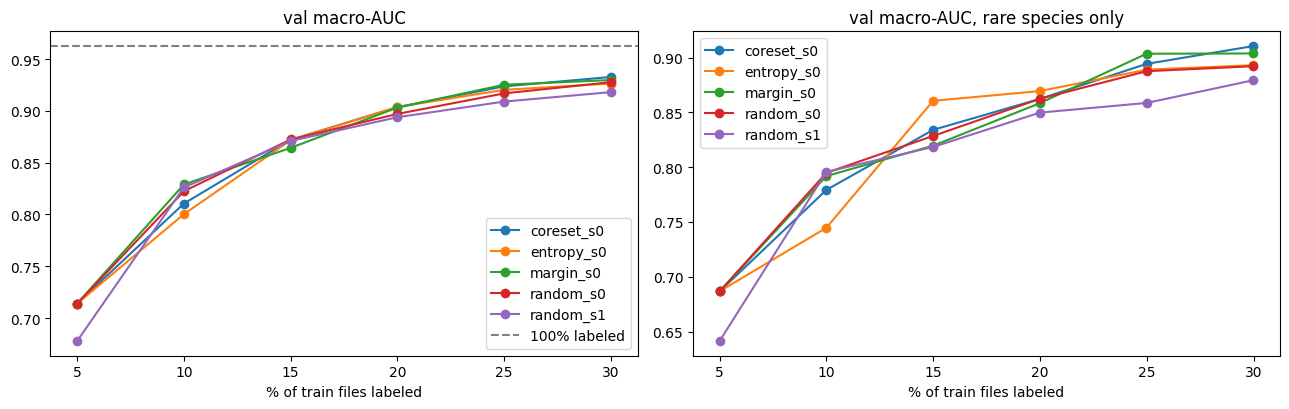

            final_macro  mean_macro  final_rare  rare_files_at_end  minutes
coreset_s0       0.9328      0.8595      0.9104              315.0     22.1
entropy_s0       0.9265      0.8561      0.8930              287.0     23.2
margin_s0        0.9299      0.8609      0.9037              232.0     23.5
random_s0        0.9278      0.8585      0.8921              198.0     20.9
random_s1        0.9182      0.8494      0.8793              181.0     20.6


In [ ]:
import glob, json
runs = {os.path.basename(p)[:-5]: pd.DataFrame(json.load(open(p))["hist"])
        for p in sorted(glob.glob(f"{AL}/*_s*.json"))}
base = json.load(open("results/baseline_metrics.json"))["val_auc"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for nm, d in runs.items():
    ax[0].plot(d.frac * 100, d.macro_auc, marker="o", label=nm)
    ax[1].plot(d.frac * 100, d.rare_auc, marker="o", label=nm)
ax[0].axhline(base, ls="--", c="gray", label="100% labeled")
ax[0].set_title("val macro-AUC"); ax[1].set_title("val macro-AUC, rare species only")
for a in ax: a.set_xlabel("% of train files labeled"); a.legend()
plt.tight_layout(); plt.savefig("results/al_curves.png", dpi=120); plt.show()

summary = pd.DataFrame({nm: dict(final_macro=d.macro_auc.iloc[-1], mean_macro=d.macro_auc.mean(),
                                 final_rare=d.rare_auc.iloc[-1], rare_files_at_end=d.rare_files.iloc[-1],
                                 minutes=round(d.train_sec.sum() / 60 + d.get("select_sec", pd.Series([0])).sum() / 60, 1))
                        for nm, d in runs.items()}).T.round(4)
print(summary)

In [ ]:
for name in ["coreset", "margin", "entropy"]:
    run_strategy(name, 1, ctx, AL)

[coreset s1] resuming after 6 finished rounds
[margin s1] resuming after 6 finished rounds
[entropy s1] resuming after 3 finished rounds


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[entropy s1] round 3: 3424 files (20%) | macro 0.9044 | rare 0.8891 | 262s train
[entropy s1] round 4: 4280 files (25%) | macro 0.9221 | rare 0.8995 | 309s train
[entropy s1] round 5: 5136 files (30%) | macro 0.9266 | rare 0.9037 | 369s train


In [ ]:
for name in ["random", "coreset", "margin"]:
    run_strategy(name, 2, ctx, AL)

[random s2] resuming after 6 finished rounds
[coreset s2] resuming after 6 finished rounds
[margin s2] resuming after 3 finished rounds


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[margin s2] round 3: 3424 files (20%) | macro 0.9062 | rare 0.8705 | 254s train
[margin s2] round 4: 4280 files (25%) | macro 0.9180 | rare 0.8851 | 312s train
[margin s2] round 5: 5136 files (30%) | macro 0.9258 | rare 0.8949 | 375s train


In [ ]:
for name in ["random", "coreset", "margin"]:
    run_strategy(name, 3, ctx, AL)

[random s3] round 0: 856 files (5%) | macro 0.6928 | rare 0.6257 | 75s train
[random s3] round 1: 1712 files (10%) | macro 0.8197 | rare 0.7898 | 123s train
[random s3] round 2: 2568 files (15%) | macro 0.8724 | rare 0.8152 | 182s train
[random s3] round 3: 3424 files (20%) | macro 0.9015 | rare 0.8629 | 243s train
[random s3] round 4: 4280 files (25%) | macro 0.9192 | rare 0.8832 | 302s train
[random s3] round 5: 5136 files (30%) | macro 0.9272 | rare 0.8922 | 362s train
[coreset s3] round 0: 856 files (5%) | macro 0.6928 | rare 0.6257 | 75s train
[coreset s3] round 1: 1712 files (10%) | macro 0.8109 | rare 0.7690 | 113s train
[coreset s3] round 2: 2568 files (15%) | macro 0.8646 | rare 0.8142 | 169s train
[coreset s3] round 3: 3424 files (20%) | macro 0.9035 | rare 0.8794 | 229s train
[coreset s3] round 4: 4280 files (25%) | macro 0.9270 | rare 0.9081 | 288s train
[coreset s3] round 5: 5136 files (30%) | macro 0.9406 | rare 0.9265 | 348s train
[margin s3] round 0: 856 files (5%) | ma

In [14]:
import glob, json, os, numpy as np, pandas as pd

def load_runs(al_dir):
    R = {}
    for p in sorted(glob.glob(f"{al_dir}/*_s*.json")):
        strat, s = os.path.basename(p)[:-5].rsplit("_s", 1)
        d = pd.DataFrame(json.load(open(p))["hist"])
        if len(d) == 6:                                  # only fully finished runs
            R[(strat, int(s))] = d
    return R

def aulc(fr, a):                                         # normalised trapezoid area
    return sum((a[i] + a[i+1]) / 2 * (fr[i+1] - fr[i]) for i in range(len(a) - 1)) / (fr[-1] - fr[0])

def frac_to_reach(fr, a, target):                        # label fraction where the curve first hits target
    if a[0] >= target: return fr[0]
    for i in range(1, len(a)):
        if a[i] >= target > a[i-1]:
            return fr[i-1] + (fr[i] - fr[i-1]) * (target - a[i-1]) / (a[i] - a[i-1])
    return np.nan                                        # never reached within budget

def speedup(fr, s_auc, r_auc):
    out = [frac_to_reach(fr, s_auc, r_auc[i]) / fr[i] for i in range(1, len(fr))]
    return np.array(out)                                 # < 1 means fewer labels than random

R = load_runs(AL)
rows = []
for (strat, s), d in R.items():
    if strat == "random" or ("random", s) not in R: continue
    r, fr = R[("random", s)], d.frac.values
    sp = speedup(fr, d.macro_auc.values, r.macro_auc.values)
    rows.append(dict(strategy=strat, seed=s,
                     d_aulc=aulc(fr, d.macro_auc.values) - aulc(fr, r.macro_auc.values),
                     d_final=d.macro_auc.iloc[-1] - r.macro_auc.iloc[-1],
                     d_rare_final=d.rare_auc.iloc[-1] - r.rare_auc.iloc[-1],
                     speedup_median=np.nanmedian(sp), rounds_not_reached=int(np.isnan(sp).sum()),
                     rare_files_ratio=d.rare_files.iloc[-1] / r.rare_files.iloc[-1]))
P = pd.DataFrame(rows)
print(P.round(4).to_string(index=False))
print("\nmean over seeds:")
print(P.groupby("strategy").agg(n_seeds=("seed", "count"), d_aulc=("d_aulc", "mean"), d_final=("d_final", "mean"),
      d_rare_final=("d_rare_final", "mean"), speedup=("speedup_median", "mean"),
      rare_files_ratio=("rare_files_ratio", "mean")).round(4))

rnd = [aulc(d.frac.values, d.macro_auc.values) for (s_, _), d in R.items() if s_ == "random"]
print("\nrandom-vs-random AULC spread:", round(max(rnd) - min(rnd), 4), "(n =", len(rnd), ")")
P.to_csv("results/al_summary.csv", index=False)

strategy  seed  d_aulc  d_final  d_rare_final  speedup_median  rounds_not_reached  rare_files_ratio
 coreset     0  0.0007   0.0050        0.0184          0.9480                   0            1.5909
 coreset     1 -0.0022   0.0171        0.0399          0.9486                   0            1.7569
 coreset     2  0.0105   0.0033        0.0291          0.8800                   0            1.8118
 coreset     3 -0.0000   0.0134        0.0343          0.9877                   0            1.6276
 entropy     0 -0.0027  -0.0013        0.0009          0.9827                   1            1.4495
 entropy     1  0.0009   0.0084        0.0245          0.9321                   0            1.5801
  margin     0  0.0028   0.0021        0.0116          0.9606                   0            1.1717
  margin     1 -0.0012   0.0118        0.0217          0.9865                   0            1.2597
  margin     2  0.0131   0.0000        0.0131          0.9579                   0            1.4529


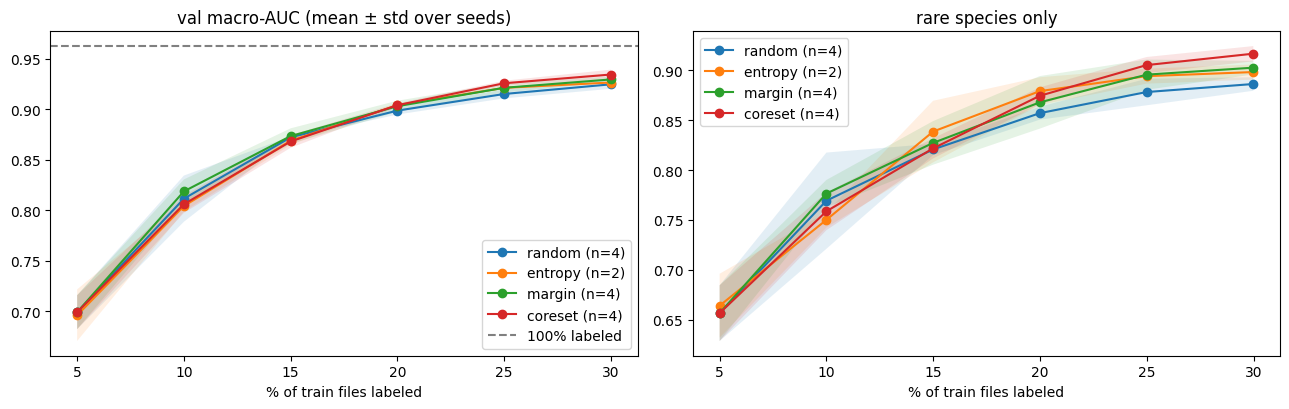

In [15]:
import matplotlib.pyplot as plt
import os, json, numpy as np, pandas as pd
base = json.load(open("results/baseline_metrics.json"))["val_auc"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for strat in ["random", "entropy", "margin", "coreset"]:
    ds = [d for (s_, _), d in R.items() if s_ == strat]
    fr = ds[0].frac.values * 100
    for a, col in zip(ax, ["macro_auc", "rare_auc"]):
        M = np.stack([d[col].values for d in ds])
        m = M.mean(0); sd = M.std(0, ddof=1) if len(ds) > 1 else 0 * m
        a.plot(fr, m, marker="o", label=f"{strat} (n={len(ds)})")
        a.fill_between(fr, m - sd, m + sd, alpha=0.12)
ax[0].axhline(base, ls="--", c="gray", label="100% labeled")
ax[0].set_title("val macro-AUC (mean ± std over seeds)"); ax[1].set_title("rare species only")
for a in ax: a.set_xlabel("% of train files labeled"); a.legend()
plt.tight_layout(); plt.savefig("results/al_curves_mean.png", dpi=120); plt.show()